In [1]:
%cd /kaggle/working
!git clone https://github.com/grip-unina/TruFor.git
!ls TruFor TruFor/test_docker TruFor/test_docker/src
!pip install -q yacs timm easydict

/kaggle/working
Cloning into 'TruFor'...
remote: Enumerating objects: 519, done.
remote: Counting objects: 100% (172/172), done.
remote: Compressing objects: 100% (99/99), done.
remote: Total 519 (delta 128), reused 73 (delta 73), pack-reused 347 (from 1)
Receiving objects: 100% (519/519), 128.18 MiB | 30.91 MiB/s, done.
Resolving deltas: 100% (222/222), done.
Updating files: 100% (116/116), done.
TruFor:
docs  README.md  test_docker  TruFor_train_test

TruFor/test_docker:
data_test	 docker_run.sh	  LICENSE.txt  src
docker_build.sh  images		  metrics.py   visualize.py
Dockerfile	 LICENSE_CMX.txt  README.md

TruFor/test_docker/src:
config.py  data_core.py  models  trufor_test.py  trufor.yaml


In [2]:
%cd /kaggle/working/TruFor/test_docker
!cat docker_build.sh | grep -i http          # shows the real download link
!wget -q https://www.grip.unina.it/download/prog/TruFor/TruFor_weights.zip -O w.zip
!md5sum w.zip                                 # README gives 7bee48f3476c75616c3c5721ab256ff8
!unzip -o -q w.zip -d weights && ls -R weights

/kaggle/working/TruFor/test_docker
7bee48f3476c75616c3c5721ab256ff8  w.zip
weights:
weights

weights/weights:
trufor.pth.tar


In [4]:
!pip install lmdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.1/572.1 kB 4.2 MB/s  0:00:00


In [6]:
import lmdb, os, glob, shutil
os.makedirs("/kaggle/working/trial/images", exist_ok=True)

BASE = "/kaggle/input/datasets/dinmkeljiame/doctamper/"
env = lmdb.open(BASE + "DocTamperV1-TestingSet", readonly=True, lock=False, readahead=False, meminit=False)
with env.begin() as txn:
    for i in range(4):
        open(f"/kaggle/working/trial/images/dt_{i}.jpg", "wb").write(txn.get(f"image-{i:09d}".encode()))
env.close()

for f in sorted(glob.glob("/kaggle/working/tsroie/test/img/*.png"))[:2]:
    shutil.copy(f, "/kaggle/working/trial/images/")
print(os.listdir("/kaggle/working/trial/images"))

['dt_0.jpg', 'dt_1.jpg', 'dt_3.jpg', 'dt_2.jpg']


In [22]:
%cd /kaggle/working/TruFor/test_docker/src
!sed -i 's/map_location=torch.device(device))/map_location=torch.device(device), weights_only=False)/' trufor_test.py
!python trufor_test.py -gpu -1 -in /kaggle/working/trial/images -out /kaggle/working/trial/out

/kaggle/working/TruFor/test_docker/src
=> loading model from ../weights/trufor.pth.tar
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
100%|█████████████████████████████████████████████| 4/4 [00:33<00:00,  8.49s/it]


dt_0.jpg {'map': (512, 512), 'imgsize': (2,), 'score': (), 'conf': (512, 512)} | score: 0.201
dt_1.jpg {'map': (512, 512), 'imgsize': (2,), 'score': (), 'conf': (512, 512)} | score: 0.096
dt_2.jpg {'map': (512, 512), 'imgsize': (2,), 'score': (), 'conf': (512, 512)} | score: 0.023
dt_3.jpg {'map': (512, 512), 'imgsize': (2,), 'score': (), 'conf': (512, 512)} | score: 0.153


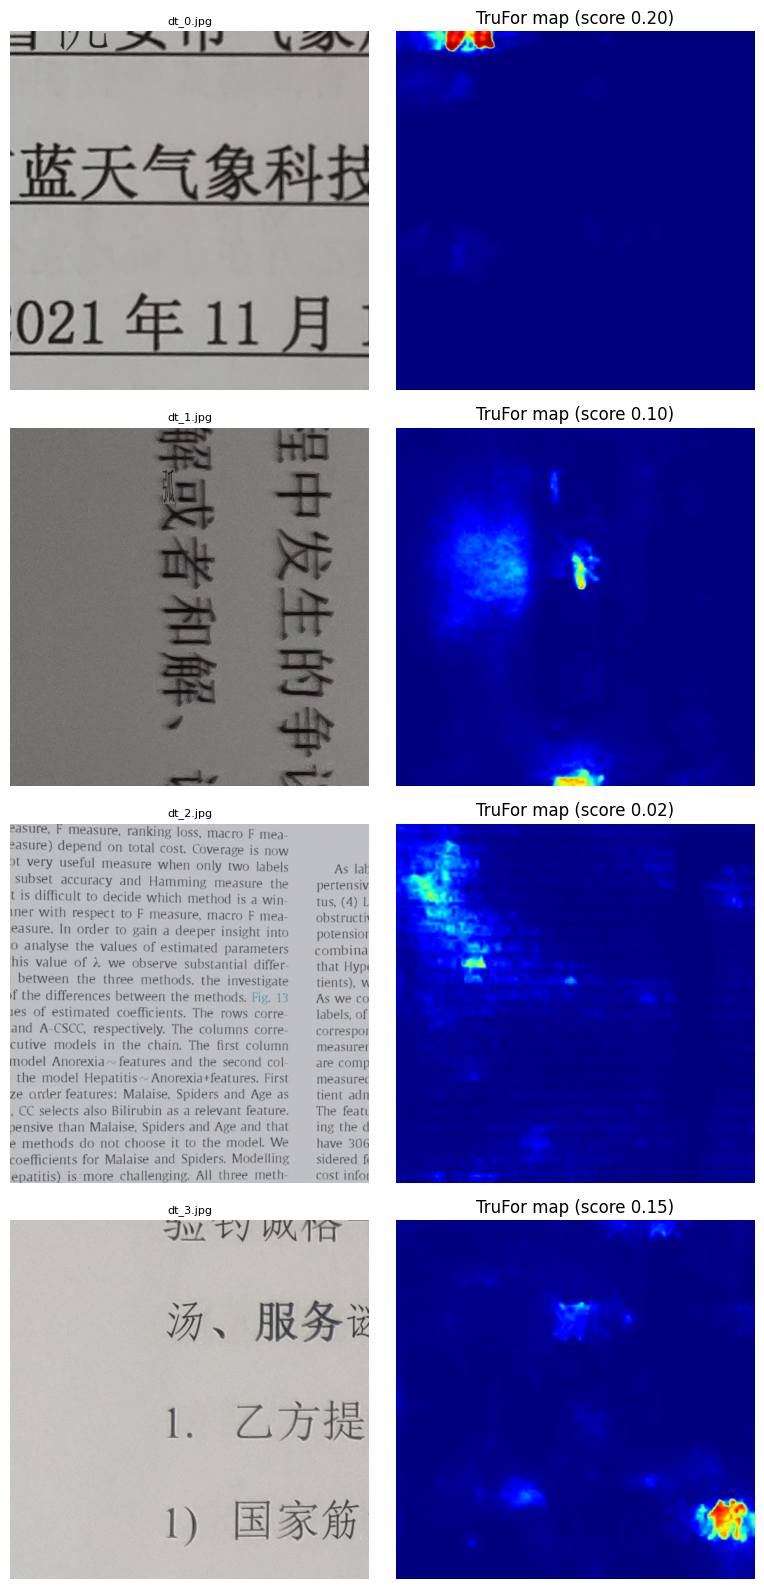

In [26]:
import numpy as np, cv2, matplotlib.pyplot as plt

files = sorted(glob.glob("/kaggle/working/trial/out/**/*.npz", recursive=True))
fig, axes = plt.subplots(len(files), 2, figsize=(8, 4 * len(files)))
for row, f in zip(np.atleast_2d(axes), files):
    d = np.load(f, allow_pickle=True)
    name = os.path.basename(f).replace(".npz", "")
    score = float(d["score"]) if "score" in d.files else float("nan")
    print(name, {k: getattr(d[k], "shape", d[k]) for k in d.files}, "| score:", round(score, 3))
    img = cv2.cvtColor(cv2.imread(f"/kaggle/working/trial/images/{name}"), cv2.COLOR_BGR2RGB)
    row[0].imshow(img); row[0].set_title(name, fontsize=8); row[0].axis("off")
    row[1].imshow(d["map"], cmap="jet", vmin=0, vmax=1); row[1].set_title(f"TruFor map (score {score:.2f})"); row[1].axis("off")
plt.tight_layout(); plt.show()

In [28]:
import lmdb, os, random, shutil
import numpy as np, cv2

BASE = "/kaggle/input/datasets/dinmkeljiame/doctamper/"   # your real path
SEED, N = 7, 5                                            # change SEED for 5 different documents

shutil.rmtree("/kaggle/working/trial2", ignore_errors=True)
os.makedirs("/kaggle/working/trial2/images", exist_ok=True)

env = lmdb.open(BASE + "DocTamperV1-TestingSet", readonly=True, lock=False, readahead=False, meminit=False)
true = {}
with env.begin() as txn:
    total = int(txn.get(b"num-samples"))
    ids = random.Random(SEED).sample(range(4, total), N)           # skip 0-3, already seen
    for i in ids:
        open(f"/kaggle/working/trial2/images/dt_{i}.jpg", "wb").write(txn.get(f"image-{i:09d}".encode()))
        m = cv2.imdecode(np.frombuffer(txn.get(f"label-{i:09d}".encode()), np.uint8), cv2.IMREAD_GRAYSCALE)
        true[i] = m > 0                                            # True = edited pixel
env.close()
print("chosen keys:", ids)

%cd /kaggle/working/TruFor/test_docker/src
!python trufor_test.py -gpu -1 -in /kaggle/working/trial2/images -out /kaggle/working/trial2/out

chosen keys: [10615, 4947, 12941, 21333, 1586]
/kaggle/working/TruFor/test_docker/src
=> loading model from ../weights/trufor.pth.tar
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
100%|█████████████████████████████████████████████| 5/5 [00:54<00:00, 10.86s/it]


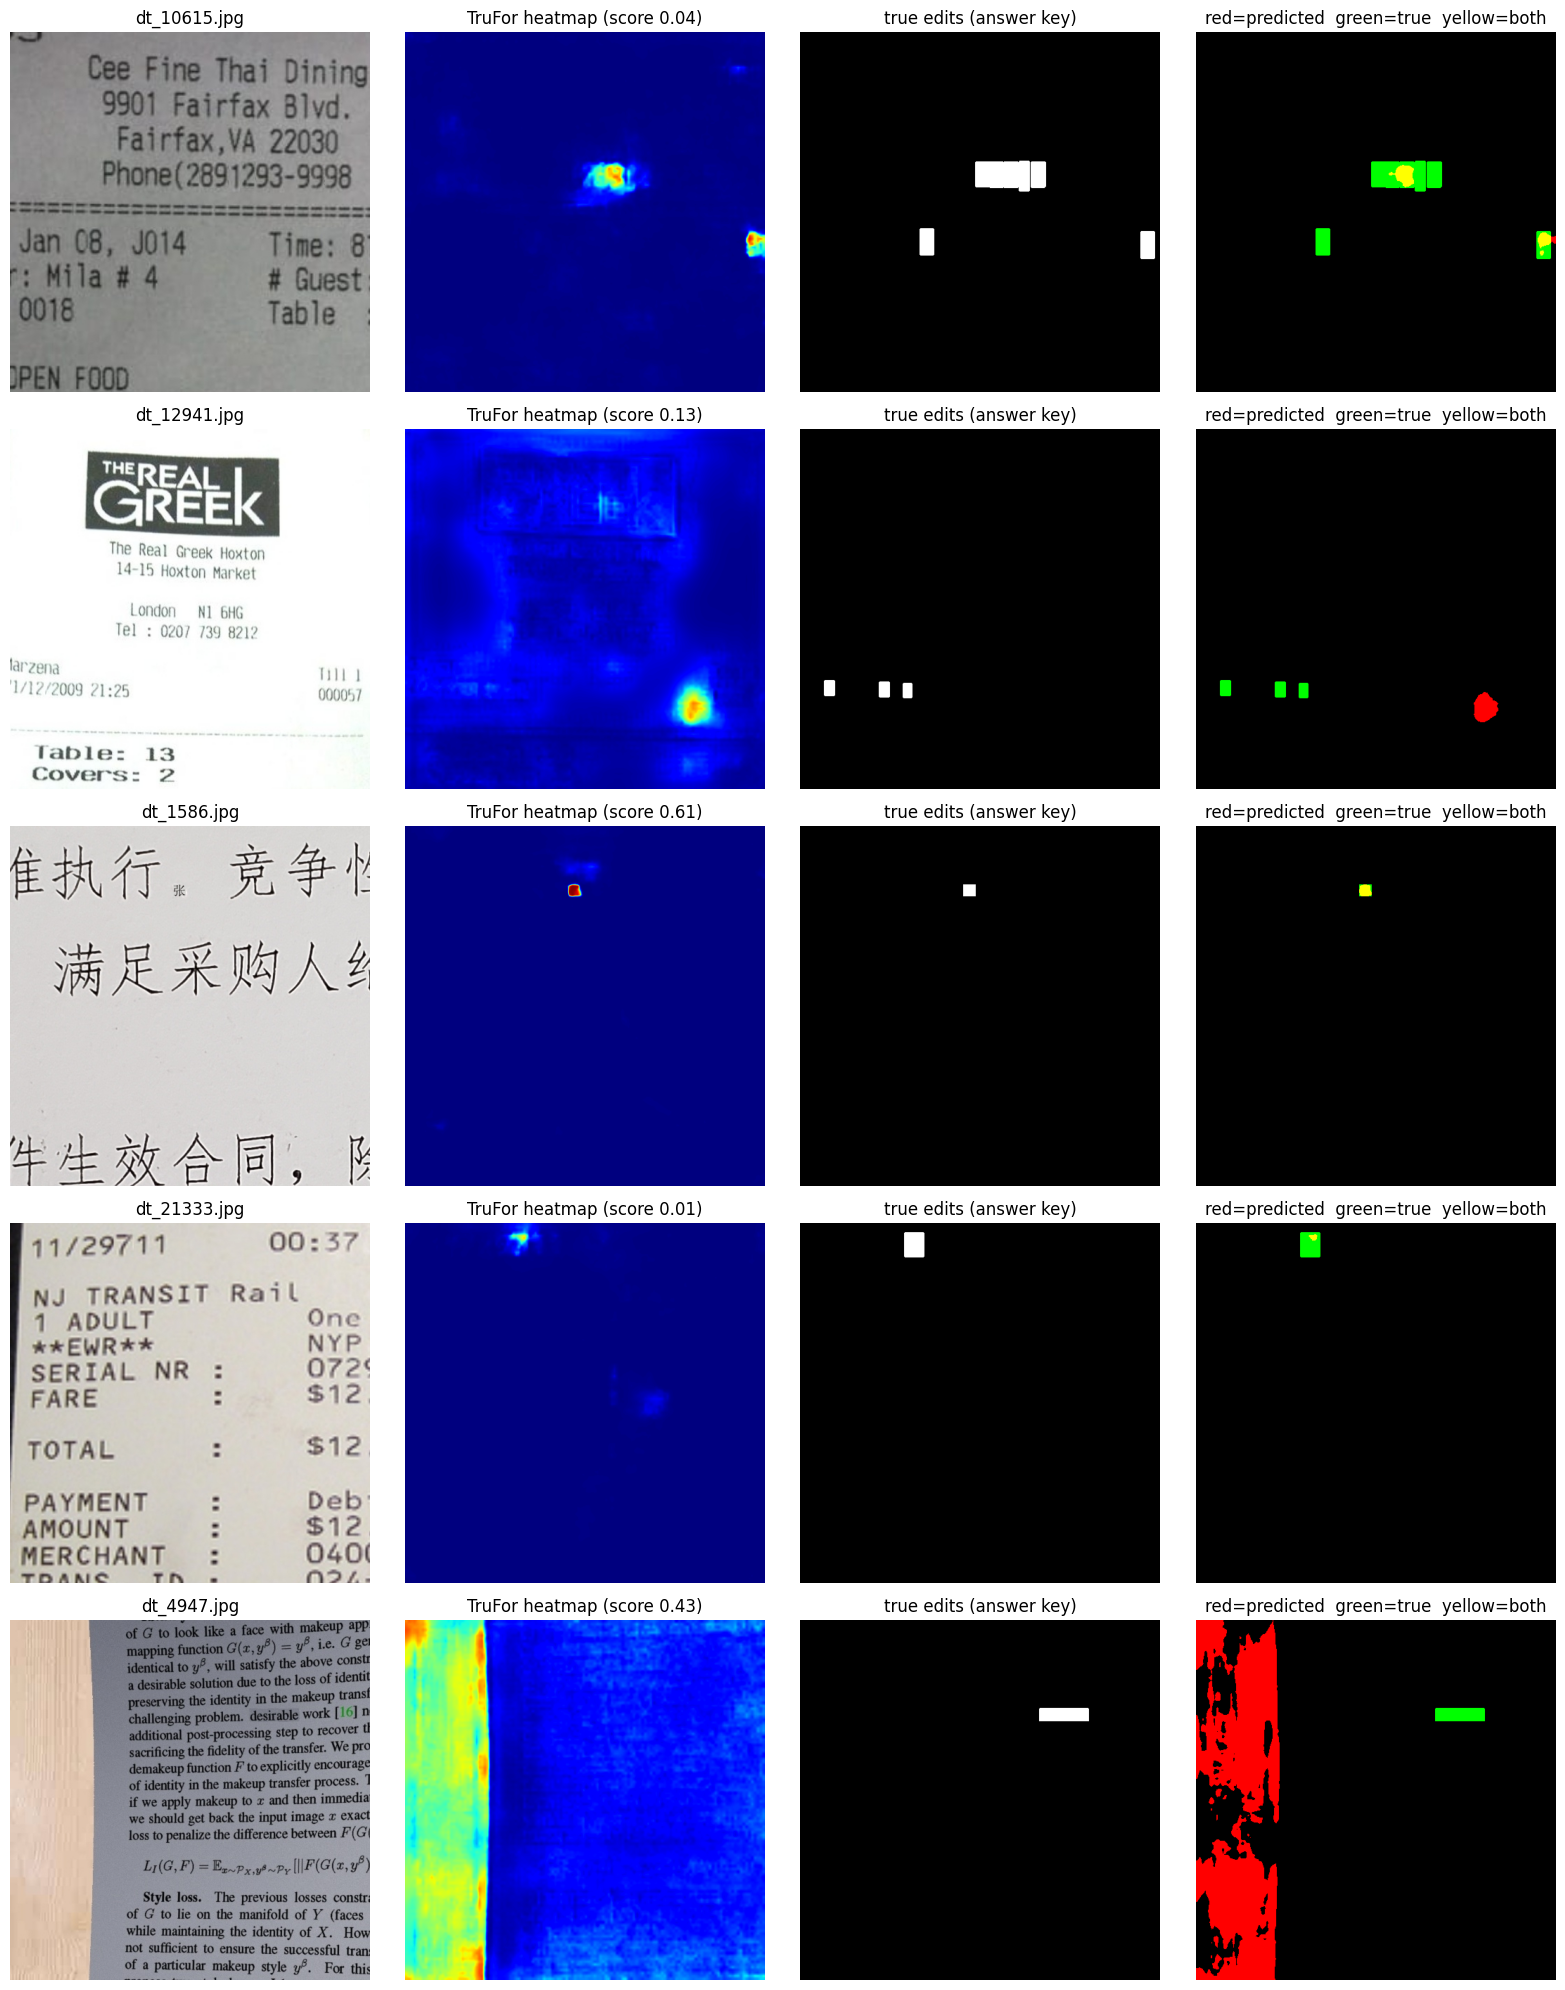

  key  edited_pct  heat_inside  heat_outside  pixel_AUC  F1_at_0_5  IoU_at_0_5  best_F1  best_thr  image_score
10615        2.10        0.265         0.007      0.975      0.307       0.181    0.694      0.05        0.037
12941        0.39        0.128         0.076      0.868      0.000       0.000    0.032      0.10        0.129
 1586        0.12        0.775         0.001      1.000      0.907       0.830    0.951      0.20        0.606
21333        0.40        0.208         0.003      0.997      0.138       0.074    0.592      0.10        0.014
 4947        0.51        0.129         0.224      0.371      0.000       0.000    0.012      0.10        0.426


In [29]:
import glob
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score

def f1_iou(pred, gt):
    tp = (pred & gt).sum(); fp = (pred & ~gt).sum(); fn = (~pred & gt).sum()
    return 2 * tp / max(2 * tp + fp + fn, 1), tp / max(tp + fp + fn, 1)

files = sorted(glob.glob("/kaggle/working/trial2/out/**/*.npz", recursive=True))
fig, axes = plt.subplots(len(files), 4, figsize=(16, 4 * len(files)))
axes = np.atleast_2d(axes)
rows = []

for ax_row, f in zip(axes, files):
    d = np.load(f, allow_pickle=True)
    name = os.path.basename(f)[:-4]                                # dt_1234.jpg
    i = int(name.split("_")[1].split(".")[0])
    gt = true[i]
    heat = d["map"].astype(np.float32)
    if heat.shape != gt.shape:
        heat = cv2.resize(heat, gt.shape[::-1])
    score = float(d["score"]) if "score" in d.files else float("nan")

    f1_05, iou_05 = f1_iou(heat > 0.5, gt)
    best_f1, best_t = max((f1_iou(heat > t, gt)[0], t) for t in np.linspace(0.05, 0.95, 19))
    rows.append(dict(key=i, edited_pct=round(100 * gt.mean(), 2),
                     heat_inside=round(float(heat[gt].mean()), 3), heat_outside=round(float(heat[~gt].mean()), 3),
                     pixel_AUC=round(roc_auc_score(gt.ravel(), heat.ravel()), 3),
                     F1_at_0_5=round(f1_05, 3), IoU_at_0_5=round(iou_05, 3),
                     best_F1=round(best_f1, 3), best_thr=round(best_t, 2), image_score=round(score, 3)))

    img = cv2.cvtColor(cv2.imread(f"/kaggle/working/trial2/images/{name}"), cv2.COLOR_BGR2RGB)
    overlay = np.zeros((*gt.shape, 3), np.uint8)
    overlay[..., 0] = (heat > 0.5) * 255          # red   = TruFor says edited
    overlay[..., 1] = gt * 255                    # green = really edited (yellow = both)
    ax_row[0].imshow(img);                              ax_row[0].set_title(name)
    ax_row[1].imshow(heat, cmap="jet", vmin=0, vmax=1); ax_row[1].set_title(f"TruFor heatmap (score {score:.2f})")
    ax_row[2].imshow(gt, cmap="gray");                  ax_row[2].set_title("true edits (answer key)")
    ax_row[3].imshow(overlay);                          ax_row[3].set_title("red=predicted  green=true  yellow=both")
    for a in ax_row: a.axis("off")

plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).to_string(index=False))